# Introduction

**Goal:** Generate novel, plausible peptides with high antimicrobial activity.

To find such peptides, we will need two things:
- 🗺️ **A Map**, which will describe a landscape of plausible peptides.
- 🧭 **A Compass**, which will guide us toward peptides with high antimicrobial activity.


The **Map** will be provided by the latent space of the variational autoencoder [HydrAMP (Szymczak et al., 2023)](https://doi.org/10.1038/s41467-023-36994-z).

The **Compass** will be an antimicrobial activity predictor, namely APEX predictor [Wan et al., 2024](https://doi.org/10.1038/s41551-024-01201-x)

Plan:
1. 🗺️ Get familiar with the "map" - HydrAMP autoencoder
2. 🧭 Get familiar with the "compass" - APEX predictor
3. ✈️ Global exploration and Optimization
4. 📍 Local Exploration and Optimization



# Installation



Run the following cell to install the required **packages** and download the model **weights and data**. This should take about **2 minutes**.

In [1]:
%pip install git+https://github.com/szczurek-lab/pep-compass@ml-in-pl-tutorial-main

!wget -c "https://github.com/szczurek-lab/pep-compass/releases/download/tutorial-v1/models.zip" -O models.zip
!wget -c "https://github.com/szczurek-lab/pep-compass/releases/download/tutorial-v1/data.zip" -O data.zip

!unzip -qo models.zip -d .
!unzip -qo data.zip -d .

!rm models.zip
!rm data.zip

  Cloning https://github.com/szczurek-lab/pep-compass (to revision ml-in-pl-tutorial-main) to /tmp/pip-req-build-gdnef27r
  Running command git clone --filter=blob:none --quiet https://github.com/szczurek-lab/pep-compass /tmp/pip-req-build-gdnef27r
  Running command git checkout -b ml-in-pl-tutorial-main --track origin/ml-in-pl-tutorial-main
  Switched to a new branch 'ml-in-pl-tutorial-main'
  branch 'ml-in-pl-tutorial-main' set up to track 'origin/ml-in-pl-tutorial-main'.
  Resolved https://github.com/szczurek-lab/pep-compass to commit 1bc6cadc48d45750c3f9ae6d9b135b0e0f1ebcab
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/MachineLearningLifeScience/poli-baselines.git (to revision main) to /tmp/pip-install-btrorqvf/poli-baselines_e2a6197f62104c909edd4f57306db733
  Running command git clone --filter=blob:none --quiet https://github.com/MachineLearningLifeScience/poli-bas

In [2]:
import warnings

import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
from IPython.display import HTML
from Levenshtein import distance
from matplotlib.animation import FuncAnimation
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA

from pep_compass.geodesic_search.geodesics import Geodesics
from pep_compass.local_enumeration.local_enumerator import (
    SamplingMutationLocalEnumerator,
)
from pep_compass.local_enumeration.mutation_enumerator import (
    MutationEnumerationInTangentSpace,
)
from pep_compass.local_enumeration.sampling_walker import (
    SecondOrderRiemannianBrownianEfficientSampling,
)
from pep_compass.models.encoder_decoder.hydramp_encoder_decoder import (
    HydrAMPEncoderDecoder,
)
from pep_compass.optimization.black_box.apex_black_box import (
    APEXBlackBox,
)
from pep_compass.optimization.black_box.list_observer import ListObserver
from pep_compass.optimization.lebo.local_enumeration_bayesian_optimizer import (
    LocalEnumerationBayesianOptimizer,
)

In [4]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


# 🗺️ **The Map** - Autoencoder


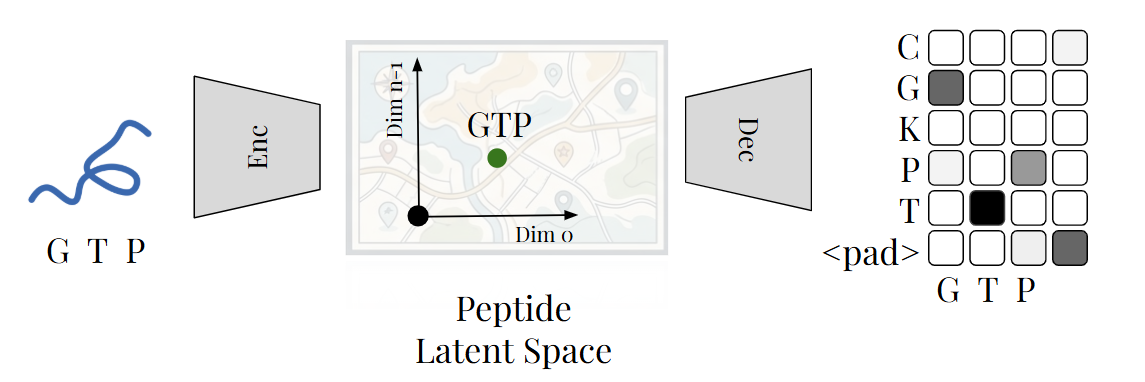


In [5]:
autoencoder = HydrAMPEncoderDecoder(device=DEVICE, models_dir="models")

Once we have the autoencoder ready, let's embed the peptides and visualize the latent space using PCA.
Let's also sample a few points from the latent space.

In [6]:
alphabet = ["<pad>"] + list("ACDEFGHIKLMNPQRSTVWY")
print(f"{alphabet=}")

alphabet=['<pad>', 'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']


In [7]:
PEPTIDE_DATASET_PATH = "data/peptides.csv"
peptide_dataset = pd.read_csv(PEPTIDE_DATASET_PATH)
background_peptides = peptide_dataset["sequence"].sample(10000, random_state=32).values

print("First 10 background peptides:")
background_peptides[:10]

First 10 background peptides:


array(['FLVTLGLNIVSGIVLKRYREVYQ', 'MLWRLVQQWSV', 'MSWKKALRIPGGLRAATVTLML',
       'AVHDRQAAELAWGRAIAFLKKRLG', 'IFMAVFKKRVVYTKYRHDRHAIK',
       'TMGNPKPSVSWVKGETVVKETARIA', 'QLLKKYKNKIISVALLAIYFFDYR',
       'MVDVAHLERMGRELKCPI', 'MLALNNNLLEGPIPLSIYQLVR',
       'MNMFTVLTSCSVWLNTQNCGT'], dtype=object)

In [8]:
latent_background = autoencoder.encode_peptides(background_peptides)
latent_background.shape

torch.Size([10000, 64])

In [9]:
# @title PCA of latent space { display-mode: "form" }


PCA_COMPONENTS = (0, 1)  # PCA components to plot

pca = PCA(n_components=64)
latent_background_projected = pca.fit_transform(
    latent_background.detach().cpu().numpy()
)

# Mean and variance in PCA space
mean = np.zeros(pca.n_components_)
variance = pca.explained_variance_

# Sample PCA coordinates
n_samples = 5

rng = np.random.default_rng(seed=42)

sampled_latent_points = rng.normal(
    loc=mean,
    scale=np.sqrt(variance),
    size=(n_samples, pca.n_components_),
)

fig = go.Figure()

background_lengths = [len(peptide) for peptide in background_peptides]

fig.add_trace(
    go.Scattergl(
        x=latent_background_projected[:, PCA_COMPONENTS[0]],
        y=latent_background_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Background peptides",
        marker={
            "size": 6,
            "opacity": 0.5,
            "color": background_lengths,
            "colorscale": "Viridis",
            "colorbar": {
                "title": "Sequence length",
                "len": 0.5,
                "y": 0.5,
                "yanchor": "middle",
                "x": 1.02,
            },
        },
        customdata=[
            (sequence, length)
            for sequence, length in zip(background_peptides, background_lengths)
        ],
        hovertemplate=(
            "Sequence: %{customdata[0]}<br>"
            "Length: %{customdata[1]}<br>"
            f"PC{PCA_COMPONENTS[0]}: " + "%{x:.4f}<br>"
            f"PC{PCA_COMPONENTS[1]}: " + "%{y:.4f}<extra></extra>"
        ),
    )
)

fig.add_trace(
    go.Scattergl(
        x=sampled_latent_points[:, PCA_COMPONENTS[0]],
        y=sampled_latent_points[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Sampled latent points",
        marker={
            "size": 10,
            "opacity": 1,
            "color": "red",
        },
        hovertemplate=(
            "Sampled latent point<br>"
            f"PC{PCA_COMPONENTS[0]}: " + "%{x:.4f}<br>"
            f"PC{PCA_COMPONENTS[1]}: " + "%{y:.4f}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title="PCA projection of latent positions",
    xaxis_title=f"PC{PCA_COMPONENTS[0]} ({pca.explained_variance_ratio_[0]:.1%} variance)",
    yaxis_title=f"PC{PCA_COMPONENTS[1]} ({pca.explained_variance_ratio_[1]:.1%} variance)",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()


Let's decode sampled latent points (red dots) and let's see how the points in the ambient space look like.

In [10]:
# Transform back to original space
latent_samples = pca.inverse_transform(sampled_latent_points)
latent_samples = torch.tensor(latent_samples, dtype=torch.float32, device=DEVICE)

with torch.inference_mode():
    ambient_decoded_samples = autoencoder.decoder_forward(
        latent_samples, softmax=True, flatten=False
    )

In [11]:
ambient_decoded_samples.shape

torch.Size([5, 25, 21])

- One ambient point is a tensor of size 25 x 21.
- 25 corresponds to maximum sequence length.
- 21 corresponds to amino-acid alphabet with additional `<pad>` character

In [12]:
print(alphabet)

['<pad>', 'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']


Let's visualize one ambient point as a table and let's inspect the content of entries.

One ambient point corresponds to a position-wise factorized probability distribution over the amino acid alphabet.
It means that on every position there is a categorical probability distribution.

In [13]:
SAMPLE_INDEX = (
    1  # Change this index to 0, 1, 2, 3, or 4 to visualize different sampled peptides
)

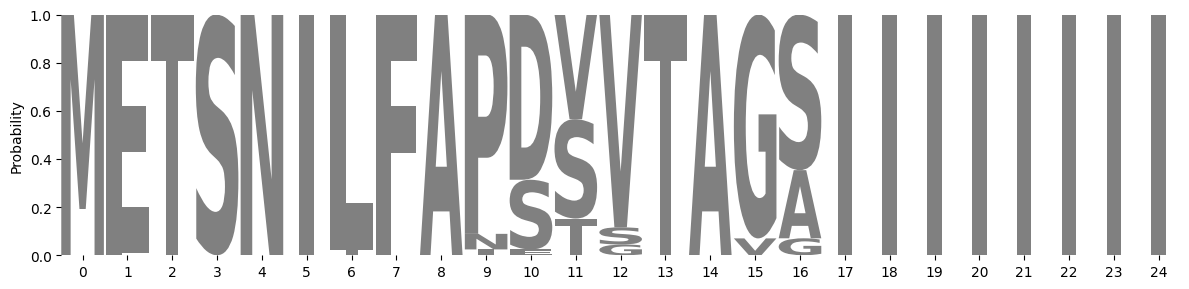

In [14]:
# @title Ambient space representation { display-mode: "form" }

decoded_sample_numpy = ambient_decoded_samples[SAMPLE_INDEX].T.detach().cpu().numpy()

color_limit = 1

fig = go.Figure(
    go.Heatmap(
        z=decoded_sample_numpy,
        y=alphabet,
        colorscale="Greens",
        zmin=0,
        zmax=1,
        colorbar={"title": "Probability"},
        hovertemplate=(
            "Position: %{x}<br>Amino acid: %{y}<br>Probability: %{z:.2}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title=f"Soft peptide",
    xaxis_title="Peptide residue",
    yaxis_title="Alphabet",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

amino_acids = ["."] + list("ACDEFGHIKLMNPQRSTVWY")


def plot_logo(matrix, ax, title="", verbose=False):

    if not verbose:
        warnings.filterwarnings("ignore")
    df = pd.DataFrame(matrix.T, columns=amino_acids)
    df.index.name = "pos"

    logo = logomaker.Logo(df, ax=ax)
    logo.style_spines(visible=False)
    logo.style_xticks(anchor=0, spacing=1)

    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Probability")


plt.figure(figsize=(12, 3))
ax = plt.gca()
plot_logo(decoded_sample_numpy, ax=ax)
plt.tight_layout()
plt.show()

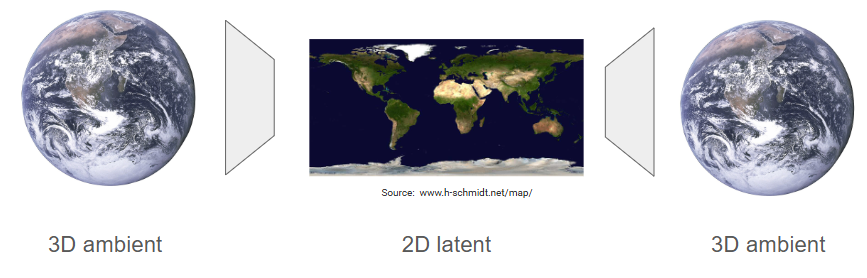

# 🧭 **The Compass** - APEX Predictor

The APEX model predicts a value called the **Minimal Inhibitory Concentration (MIC)**.

MIC represents the lowest concentration of a peptide required to stop bacterial growth. Therefore, **lower MIC values indicate more active peptides**. Our goal is thus to **minimize the predicted MIC**.

Exact MIC measurement requires wet lab validation. APEX predictor approximates MIC against E. coli basteria:
- $MIC_1$: E. coli ATCC 11775
- $MIC_2$: E. coli AIG221
- $MIC_3$: E. coli AIG222

Then we $log_2$ predicted $MIC_i$ values then we take mean. So the score is:

$$\frac{1}{3} \sum^3_{i=1} log_2 MIC_i$$


In [15]:
# Create the APEX predictor

apex_predictor = APEXBlackBox(
    mic_aggregate="mean",
    mic_bacteria=[1, 2, 3],
    device=DEVICE,
    models_dir="models"
)

In [16]:
veltri_positive_dataset = peptide_dataset[
    peptide_dataset["dataset"].str.contains("hydramp_veltri_positive")
]
positive_sample = (
    veltri_positive_dataset["sequence"].sample(300, random_state=42).values
)

print("First 10 positive peptides:")
positive_sample[:10]

First 10 positive peptides:


array(['MRILSIIRWTRMKKSSA', 'GLHKVMREVLGYERNSYKKFFLR',
       'GVGDLIRKAVSVIKNIV', 'NLLNDALGTVNGLLGRS', 'AWRWKAFRNCWRVRSSSL',
       'FLSLALAALPKLFCLIFKKC', 'FLSLLPSIVSGAVSLAKKL',
       'GCSYSTRPYFLRWRLKFKSKVWCG', 'FLPGLIKAAVGVGSTILCKITKKC',
       'FIRWRFRWWRWRR'], dtype=object)

In [17]:
scores = apex_predictor(positive_sample)[:, 0]

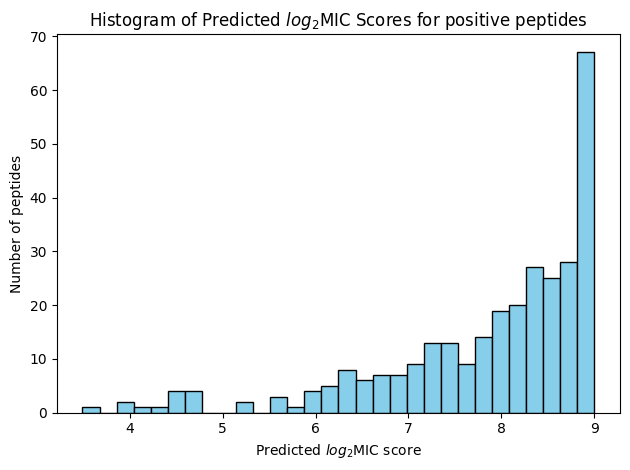

In [18]:
plt.hist(scores, bins=30, color="skyblue", edgecolor="black")

plt.xlabel("Predicted $log_2$MIC score")
plt.ylabel("Number of peptides")
plt.title("Histogram of Predicted $log_2$MIC Scores for positive peptides")

plt.tight_layout()
plt.show()

In [19]:
# @title Positive peptides in latent space { display-mode: "form" }

PCA_COMPONENTS = (0, 1)

latent_positive = autoencoder.encode_peptides(positive_sample)

projected_positive = pca.transform(latent_positive.detach().cpu().numpy())

fig = go.Figure()

fig.add_trace(
    go.Scattergl(
        x=latent_background_projected[:, PCA_COMPONENTS[0]],
        y=latent_background_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Background peptides",
        hoverinfo="skip",
        marker={
            "size": 6,
            "opacity": 0.2,
            "color": "gray",
        },
    )
)

fig.add_trace(
    go.Scattergl(
        x=projected_positive[:, PCA_COMPONENTS[0]],
        y=projected_positive[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Positive peptides",
        marker={
            "size": 12,
            "color": scores,
            "opacity": 0.8,
            "colorscale": "Viridis",
            "colorbar": {
                "title": "Log2MIC score",
                "len": 0.5,
                "y": 0.5,
                "yanchor": "middle",
                "x": 1.02,
            },
        },
        customdata=np.column_stack((positive_sample, scores, np.arange(len(positive_sample)))),
        hovertemplate=("Sequence: %{customdata[0]}<br>Score: %{customdata[1]:.4f}<br>Index: %{customdata[2]}"),
    )
)

fig.update_layout(
    title="Interactive PCA projection of latent positions",
    xaxis_title=f"PC{PCA_COMPONENTS[0]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[0]]:.1%} variance)",
    yaxis_title=f"PC{PCA_COMPONENTS[1]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[1]]:.1%} variance)",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

# ✈️ Global exploration and Optimization


To explore globally we would like to **interpolate** between two known peptides and spot some **peptide inbetween** which have low MIC score.

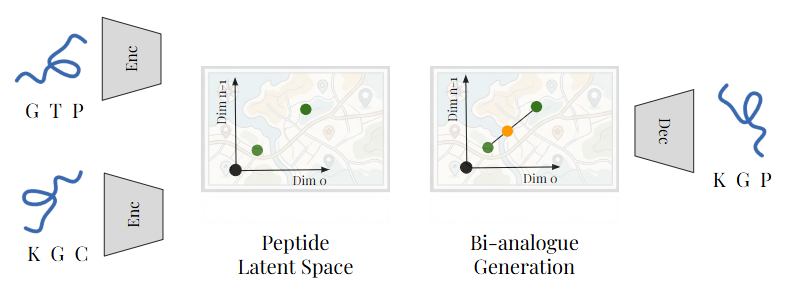

2. Choose a two prototypes with low MIC. Show their MIC.

In [ ]:
start = "ILRWKKRKLVWKR"
end = "FLILRWSRFARVLL"

print(f"Start sequence: {start}")
print(f"End sequence: {end}")

Start sequence: ILRWKKRKLVWKR
End sequence: FLILRWSRFARVLL


In [60]:
start_score, end_score = apex_predictor(np.array([start, end]))[:, 0]
print(f"log2 MIC score for the start sequence {start}: {start_score:.4f}")
print(f"log2 MIC score for the end sequence {end}: {end_score:.4f}")

log2 MIC score for the start sequence KFWARGRKPWKLAIQILK: 1.8969
log2 MIC score for the end sequence ILRWKKRWKVWLR: 0.4456


In [61]:
start_latent = autoencoder.encode_peptides([start])[0]
end_latent = autoencoder.encode_peptides([end])[0]

In [62]:
# Naive linear interpolation

POINTS_DENSITY = 90  # Number of points per unit distance in latent space

n_points = int(POINTS_DENSITY * torch.dist(end_latent, start_latent, p=2))

linear_interpolation = torch.stack(
    [
        start_latent + (i / (n_points - 1)) * (end_latent - start_latent)
        for i in range(n_points)
    ],
    dim=0,
)

interpolation_sequences = autoencoder.decode_peptides(linear_interpolation)

interpolation_sequences

['KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKPWKLAIQILK',
 'KFWARGRKP

In [65]:
unique_sequences, inverse_indices = np.unique(
    interpolation_sequences,
    return_inverse=True,
)

unique_scores = np.asarray(
    apex_predictor(unique_sequences)[:, 0],
    dtype=np.float32,
)

# Restore scores to the original interpolation path order.
linear_interpolation_scores = unique_scores[inverse_indices]

print(f"Scored {len(unique_sequences)} unique sequences.")
print(f"Total path points: {len(interpolation_sequences)}")
print(linear_interpolation_scores.shape)

Scored 48 unique sequences.
Total path points: 792
(792,)


In [66]:
# @title Linear interpolation in latent space { display-mode: "form" }

PCA_COMPONENTS = (0, 1)

projected_linear_interpolation = pca.transform(
    linear_interpolation.detach().cpu().numpy()
)


fig = go.Figure()

fig.add_trace(
    go.Scattergl(
        x=latent_background_projected[:, PCA_COMPONENTS[0]],
        y=latent_background_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Background peptides",
        hoverinfo="skip",
        marker={
            "size": 6,
            "opacity": 0.2,
            "color": "gray",
        },
    )
)


fig.add_trace(
    go.Scattergl(
        x=projected_linear_interpolation[:, PCA_COMPONENTS[0]],
        y=projected_linear_interpolation[:, PCA_COMPONENTS[1]],
        mode="lines+markers",
        name="Linear interpolation",
        line={"color": "gray", "width": 2},
        marker={
            "size": 6,
            "color": linear_interpolation_scores,
            "colorscale": "Viridis",
            "showscale": True,
            "colorbar": {
                "title": "Log2MIC score",
                "len": 0.5,
                "y": 0.5,
                "yanchor": "middle",
                "x": 1.02,
            },
        },
        customdata=np.column_stack(
            (
                np.arange(n_points),
                interpolation_sequences,
                linear_interpolation_scores,
            )
        ),
        hovertemplate=(
            "Path point: %{customdata[0]}<br>"
            "Sequence: %{customdata[1]}<br>"
            "Log2MIC: %{customdata[2]:.4f}<extra></extra>"
        ),
    )
)

endpoint_projection = projected_linear_interpolation[[0, -1]]
endpoint_sequences = [start, end]
endpoint_scores = [start_score, end_score]
endpoint_names = ["Start", "End"]

fig.add_trace(
    go.Scattergl(
        x=endpoint_projection[:, PCA_COMPONENTS[0]],
        y=endpoint_projection[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Interpolation endpoints",
        marker={"size": 14, "color": ["green", "red"]},
        customdata=np.column_stack(
            (endpoint_names, endpoint_sequences, endpoint_scores)
        ),
        hovertemplate=(
            "%{customdata[0]}<br>"
            "Sequence: %{customdata[1]}<br>"
            "Log2MIC: %{customdata[2]:.4f}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title="PCA projection of latent positions",
    xaxis_title=f"PC{PCA_COMPONENTS[0]} ({pca.explained_variance_ratio_[0]:.1%} variance)",
    yaxis_title=f"PC{PCA_COMPONENTS[1]} ({pca.explained_variance_ratio_[1]:.1%} variance)",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

In [67]:
# @title MIC score along the interpolation { display-mode: "form" }

fig = go.Figure(
    go.Scatter(
        x=np.arange(len(linear_interpolation_scores)),
        y=linear_interpolation_scores,
        mode="lines+markers",
        line={"color": "blue"},
        marker={"size": 6},
        customdata=list(zip(interpolation_sequences, linear_interpolation_scores)),
        hovertemplate=(
            "Path point: %{x}<br>"
            "Sequence: %{customdata[0]}<br>"
            "log2 MIC: %{customdata[1]:.4f}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title="Predicted log2 MIC along linear interpolation",
    xaxis_title="Interpolation point",
    yaxis_title="Predicted log2 MIC",
    template="plotly_white",
    width=900,
    height=500,
)

fig.show()

In [68]:
geo_lin = Geodesics(
    encoder_decoder=autoencoder,
    device=DEVICE,
    lr=0.001,
    patience=100,
    convergence_tol=1e-8,
    weight_ambient_dist=1,
    weight_latent_dist=0.1,
    weight_var=0,
    metric_weight=0.01,
    metric=["antex"],
    models_path="models",
)

In [69]:
pogs_line, geo_length = geo_lin.find(
    end=end_latent, begin=start_latent, num_iterations=1000, verbose=True
)

geo_length

iteration=0, loss=1304.48, ambient_dist=1303.60, latent_dist=0.92, var=0.00, lr=[0.001]
iteration=1, loss=1460.59, ambient_dist=1459.67, latent_dist=1.15, var=0.00, lr=[0.001]
iteration=2, loss=2881.12, ambient_dist=2879.97, latent_dist=1.10, var=0.00, lr=[0.001]
iteration=3, loss=2064.55, ambient_dist=2063.45, latent_dist=1.11, var=0.00, lr=[0.001]
iteration=4, loss=2174.95, ambient_dist=2173.84, latent_dist=1.11, var=0.00, lr=[0.001]
iteration=5, loss=2062.39, ambient_dist=2061.28, latent_dist=1.08, var=0.00, lr=[0.001]
iteration=6, loss=1863.36, ambient_dist=1862.28, latent_dist=1.07, var=0.00, lr=[0.001]
iteration=7, loss=1762.67, ambient_dist=1761.60, latent_dist=1.06, var=0.00, lr=[0.001]
iteration=8, loss=1721.02, ambient_dist=1719.96, latent_dist=1.06, var=0.00, lr=[0.001]
iteration=9, loss=1688.44, ambient_dist=1687.38, latent_dist=1.05, var=0.00, lr=[0.001]
iteration=10, loss=1625.15, ambient_dist=1624.10, latent_dist=1.04, var=0.00, lr=[0.001]
iteration=11, loss=1577.11, amb

1104.500244140625

In [70]:
pogs_sequences = autoencoder.decode_peptides(pogs_line)

In [71]:
unique_pogs_sequences, inverse_pogs_indices = np.unique(
    pogs_sequences,
    return_inverse=True,
)

unique_scores = np.asarray(
    apex_predictor(unique_pogs_sequences)[:, 0],
    dtype=np.float32,
)

# Restore scores to the original interpolation path order.
pogs_interpolation_scores = unique_scores[inverse_pogs_indices]

print(f"Scored {len(unique_pogs_sequences)} unique sequences.")
print(f"Total path points: {len(pogs_sequences)}")
print(pogs_interpolation_scores.shape)

Scored 45 unique sequences.
Total path points: 792
(792,)


In [72]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=np.arange(len(linear_interpolation_scores)),
        y=linear_interpolation_scores,
        name="Linear interpolation",
        mode="lines+markers",
        line={"color": "blue"},
        marker={"size": 6},
        customdata=list(zip(interpolation_sequences, linear_interpolation_scores)),
        hovertemplate=(
            "Path point: %{x}<br>"
            "Sequence: %{customdata[0]}<br>"
            "log2 MIC: %{customdata[1]:.4f}<extra></extra>"
        ),
    )
)

fig.add_trace(
    go.Scatter(
        x=np.arange(len(pogs_interpolation_scores)),
        y=pogs_interpolation_scores,
        name="POGS interpolation",
        mode="lines+markers",
        line={"color": "red"},
        marker={"size": 6},
        customdata=list(zip(pogs_sequences, pogs_interpolation_scores)),
        hovertemplate=(
            "Path point: %{x}<br>"
            "Sequence: %{customdata[0]}<br>"
            "log2 MIC: %{customdata[1]:.4f}<extra></extra>"
        ),
    )
)



fig.update_layout(
    title="Predicted log2 MIC along geodesic interpolation",
    xaxis_title="Interpolation point",
    yaxis_title="Predicted log2 MIC",
    template="plotly_white",
    width=900,
    height=500,
)

fig.show()

# 📍 Local Exploration and Optimization

Given a **central peptide** we want to find its **neighbours**.

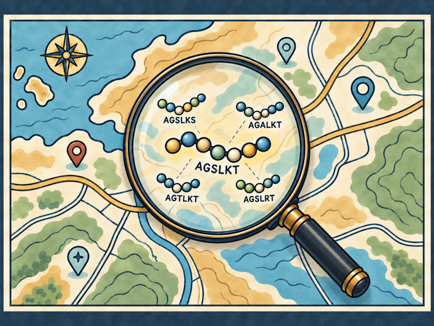

Generated using ChatGPT

## 🐎 **MUTANG** - **MU**ation Enumeration in **TANG**ent Space


In [77]:
peptide = "IKALIRKWILRPIKRLKDKFWK"

peptide_latent = autoencoder.encode_peptides([peptide])
decoded_peptide = autoencoder.decode_peptides(peptide_latent)[0]
decoded_softpeptide = autoencoder.decoder_forward(
    peptide_latent, softmax=True, flatten=False
)[0]

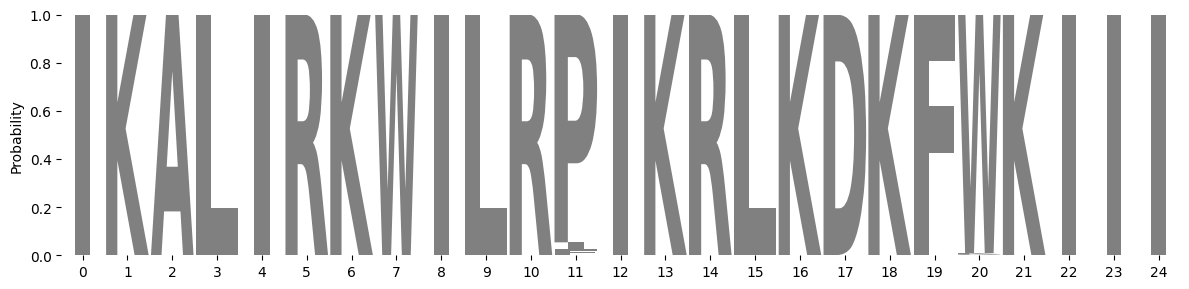

In [79]:
# @title Soft peptide { display-mode: "form" }


decoded_sample_numpy = decoded_softpeptide.T.detach().cpu().numpy()

color_limit = 1

fig = go.Figure(
    go.Heatmap(
        z=decoded_sample_numpy,
        y=alphabet,
        colorscale="Greens",
        zmin=0,
        zmax=1,
        colorbar={"title": "Probability"},
        hovertemplate=(
            "Position: %{x}<br>Amino acid: %{y}<br>Probability: %{z:.2}<extra></extra>"
        ),
    )
)

fig.update_layout(
    title=f"Soft peptide",
    xaxis_title="Peptide residue",
    yaxis_title="Alphabet",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

amino_acids = list(".ACDEFGHIKLMNPQRSTVWY")


def plot_logo(matrix, ax, title="", verbose=False):

    if not verbose:
        warnings.filterwarnings("ignore")
    df = pd.DataFrame(matrix.T, columns=amino_acids)
    df.index.name = "pos"

    logo = logomaker.Logo(df, ax=ax)
    logo.style_spines(visible=False)
    logo.style_xticks(anchor=0, spacing=1)

    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Probability")


plt.figure(figsize=(12, 3))
ax = plt.gca()
plot_logo(decoded_sample_numpy, ax=ax)
plt.tight_layout()
plt.show()

In [80]:
jacobian = autoencoder.decoder_jacobian(peptide_latent)[0]
jacobian.shape

torch.Size([525, 64])

What is the Jacobian of the decoder? It is a **local coordinate system**! One little step on the map in the $x_i$ direction causes displacement in the $u_i$ direction on the manifold.  

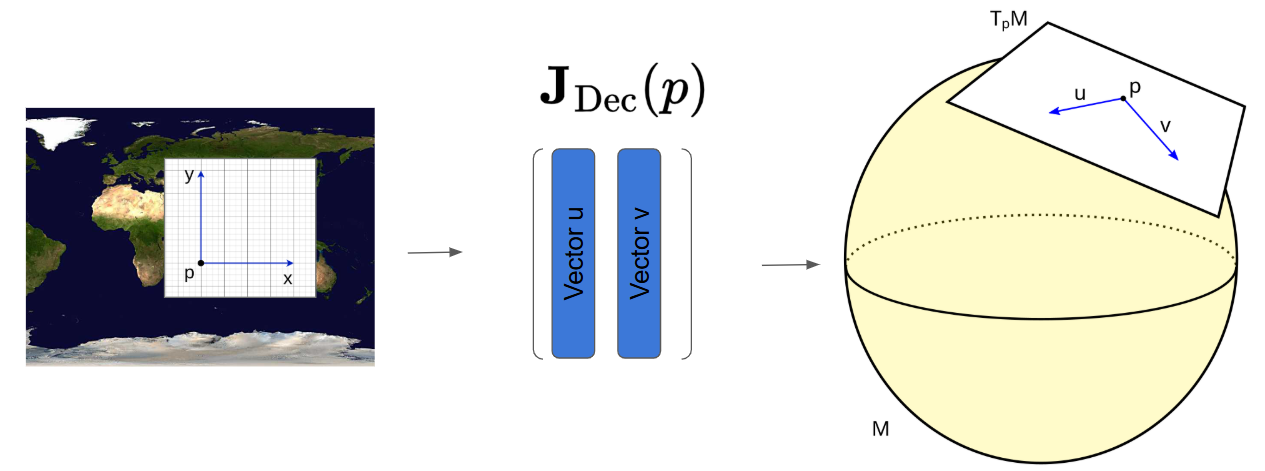

In [82]:
left, singular, right = torch.linalg.svd(
    jacobian,
    full_matrices=False,
)

In [83]:
print(f"{left.shape=}")
print(f"{right.shape=}")
print(f"{singular.shape=}")

left.shape=torch.Size([525, 64])
right.shape=torch.Size([64, 64])
singular.shape=torch.Size([64])


And what is **Singular Value Decomposition** of the Jacobian of the decoder? It is a **rotated local coordinate system**! It is rotated in such a way that one little step on the map in $x_i'$ direction causes displacement of $\sigma_i$ little steps in $u_i'$ direction .

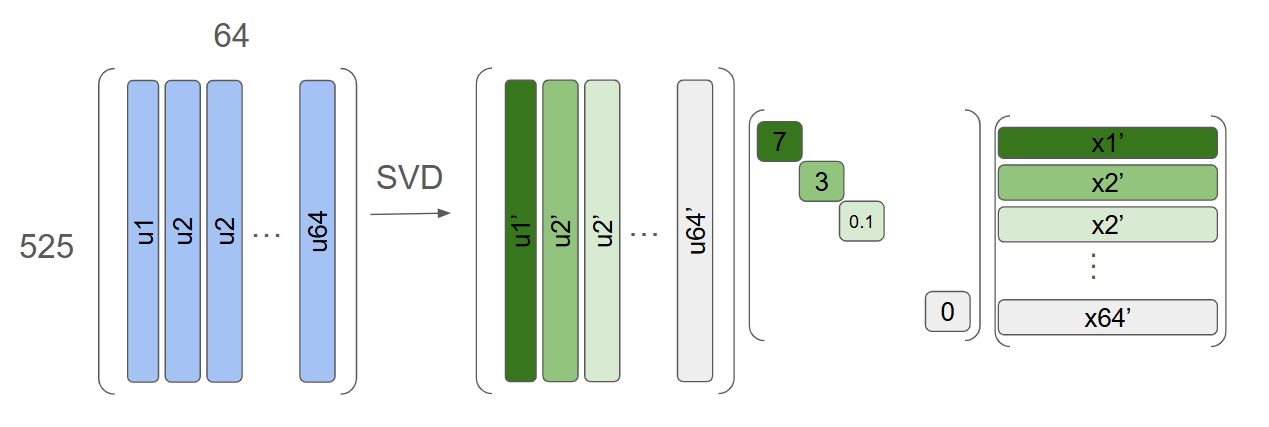

Let's inspect singular values.

In [84]:
SINGULAR_VALUE_THRESHOLD = 0.001

In [86]:
# @title Singular values { display-mode: "form" }


singular_values = singular.detach().cpu().numpy()

exponents = range(
    int(np.floor(np.log10(singular_values.min()))),
    int(np.ceil(np.log10(singular_values.max()))) + 1,
)

fig = go.Figure(
    go.Scatter(
        x=np.arange(len(singular_values)),
        y=singular_values,
        mode="lines+markers",
        customdata=singular_values,
        hovertemplate=(
            "Component: %{x}<br>Singular value: %{y:.6g}<br><extra></extra>"
        ),
    )
)

fig.add_hline(
    y=SINGULAR_VALUE_THRESHOLD,
    line_dash="dot",
    line_color="red",
    # annotation_text="Threshold",
    # annotation_position="bottom right",
)

fig.update_layout(
    title="Singular values",
    xaxis_title="Component",
    yaxis_title="Singular value",
    width=800,
    yaxis={
        "type": "log",
        "tickvals": [10**e for e in exponents],
        "ticktext": [f"10<sup>{e}</sup>" for e in exponents],
    },
    template="plotly_white",
)

fig.show()

In [88]:
# @title Left singular vectors { display-mode: "form" }

selected_components = torch.where(singular > SINGULAR_VALUE_THRESHOLD)[0].tolist()

x_labels = list(decoded_peptide) + ["<pad>"] * (25 - len(decoded_peptide))

positions = np.arange(25)
customdata = np.zeros((len(alphabet), 25, 2), dtype=object)
customdata[:, :, 0] = positions
customdata[:, :, 1] = np.array(x_labels)

ncols = 3
first_component = selected_components[0]
remaining_components = selected_components[1:]
small_rows = int(np.ceil(len(remaining_components) / ncols))
nrows = 1 + small_rows

component_matrices = {
    component: (left[:, component].reshape(25, len(alphabet)).T.detach().cpu().numpy())
    for component in selected_components
}

global_color_limit = max(np.abs(matrix).max() for matrix in component_matrices.values())

subplot_titles = [
    f"Component {first_component} (σ={singular_values[first_component]:.3g})",
]

subplot_titles.extend(
    [
        f"Component {component} (σ={singular_values[component]:.3g})"
        for component in remaining_components
    ]
)
subplot_titles.extend([""] * (nrows * ncols - len(subplot_titles)))

specs = [[{"colspan": 3}, None, None]] + [
    [{"type": "heatmap"} for _ in range(ncols)] for _ in range(small_rows)
]

fig_grid = make_subplots(
    rows=nrows,
    cols=ncols,
    specs=specs,
    subplot_titles=subplot_titles,
    vertical_spacing=0.08,
    row_heights=[3] + [1] * small_rows,
)


def add_component_heatmap(component, row, col, showscale=False):
    matrix = component_matrices[component]

    component_customdata = np.empty((len(alphabet), 25, 2), dtype=object)
    component_customdata[:, :, 0] = positions
    component_customdata[:, :, 1] = np.array(x_labels)

    fig_grid.add_trace(
        go.Heatmap(
            z=matrix,
            x=positions,
            y=alphabet,
            colorscale="RdBu_r",
            zmid=0,
            zmin=-global_color_limit,
            zmax=global_color_limit,
            showscale=showscale,
            customdata=component_customdata,
            hovertemplate=(
                "Position: %{customdata[0]}<br>"
                "Residue: %{customdata[1]}<br>"
                "Alphabet: %{y}<br>"
                "Loading: %{z:.3f}<extra></extra>"
            ),
        ),
        row=row,
        col=col,
    )


# First singular vector: large, full-width plot.
add_component_heatmap(
    first_component,
    row=1,
    col=1,
    showscale=True,
)

# Remaining singular vectors: smaller grid.
for index, component in enumerate(remaining_components):
    row, col = divmod(index, ncols)
    add_component_heatmap(
        component,
        row=row + 2,
        col=col + 1,
    )

fig_grid.update_layout(
    title="Left singular vectors",
    template="plotly_white",
    width=900,
    height=800 + 230 * small_rows,
    xaxis={
        "tickmode": "array",
        "tickvals": np.arange(25),
        "ticktext": x_labels,
    },
)

fig_grid.show()


In [89]:
POSITION_THRESHOLD = 0.1

In [90]:
mutang = MutationEnumerationInTangentSpace(
    direction_significance_threshold=SINGULAR_VALUE_THRESHOLD,
    token_threshold=POSITION_THRESHOLD,
)

In [91]:
mutations = mutang.get_mutations_from_s_u(
    singular.detach().cpu().numpy(), left.detach().cpu().numpy()
)

print("Position-wise Mutation Candidates:\n")
for i, aa in enumerate(peptide):
    print(f"{i}:", set([aa] + [alphabet[aa_index] for aa_index in mutations[i]]))

Position-wise Mutation Candidates:

0: {'I'}
1: {'K'}
2: {'A'}
3: {'L'}
4: {'I'}
5: {'R'}
6: {'K'}
7: {'W'}
8: {'I', 'P'}
9: {'L'}
10: {'R'}
11: {'F', 'I', 'P'}
12: {'I'}
13: {'K'}
14: {'R'}
15: {'I', 'L'}
16: {'K'}
17: {'A', 'D', 'S', 'G', 'E'}
18: {'K', 'W'}
19: {'F', 'Y', 'C'}
20: {'Q', 'K', 'W'}
21: {'K'}


In [92]:
mutants = mutang.mutate(
    peptide, singular.detach().cpu().numpy(), left.detach().cpu().numpy()
)
mutants = list(mutants)

In [93]:
len(mutants)

1080

If we lower a POSITION_THRESHOLD we should expect:
- a) More mutants
- b) Less mutants

Why?

In [ ]:
mutants

['IKALIRKWILRIIKRLKSWCWK',
 'IKALIRKWILRPIKRLKAKCQK',
 'IKALIRKWILRPIKRLKEWYWK',
 'IKALIRKWPLRFIKRLKEKYQK',
 'IKALIRKWILRIIKRIKAKYWK',
 'IKALIRKWILRIIKRLKSWFKK',
 'IKALIRKWPLRIIKRIKGKYQK',
 'IKALIRKWPLRPIKRIKDKCQK',
 'IKALIRKWPLRFIKRIKGWCQK',
 'IKALIRKWILRIIKRLKDWYQK',
 'IKALIRKWILRIIKRIKGKFKK',
 'IKALIRKWILRPIKRLKEWFKK',
 'IKALIRKWILRIIKRIKEWFKK',
 'IKALIRKWPLRIIKRLKDWCQK',
 'IKALIRKWILRIIKRLKDWYKK',
 'IKALIRKWPLRPIKRIKGKCKK',
 'IKALIRKWPLRIIKRIKDWCKK',
 'IKALIRKWILRPIKRLKEKCQK',
 'IKALIRKWPLRIIKRLKGKFWK',
 'IKALIRKWILRFIKRIKGKYKK',
 'IKALIRKWILRIIKRIKSKFWK',
 'IKALIRKWILRFIKRLKDKYQK',
 'IKALIRKWPLRIIKRIKGKCKK',
 'IKALIRKWILRFIKRIKAKCWK',
 'IKALIRKWPLRPIKRIKGKYQK',
 'IKALIRKWPLRIIKRLKAWCWK',
 'IKALIRKWPLRIIKRIKGWCKK',
 'IKALIRKWPLRIIKRLKEWYKK',
 'IKALIRKWPLRFIKRIKDKYKK',
 'IKALIRKWILRPIKRIKDWYKK',
 'IKALIRKWPLRPIKRIKSKCQK',
 'IKALIRKWILRFIKRLKSKCWK',
 'IKALIRKWPLRIIKRIKAKFKK',
 'IKALIRKWPLRFIKRIKDKCWK',
 'IKALIRKWPLRIIKRLKAWYKK',
 'IKALIRKWPLRFIKRLKEKCKK',
 'IKALIRKWPLRFIKRLKSWCKK',
 

In [95]:
# @title Mutants in latent space { display-mode: "form" }


PCA_COMPONENTS = (0, 1)

latent_mutants = autoencoder.encode_peptides(mutants)

latent_mutants_projected = pca.transform(latent_mutants.detach().cpu().numpy())
peptide_latent_projected = pca.transform(peptide_latent.detach().cpu().numpy())


fig = go.Figure()

fig.add_trace(
    go.Scattergl(
        x=latent_background_projected[:, PCA_COMPONENTS[0]],
        y=latent_background_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Background peptides",
        marker={
            "size": 6,
            "opacity": 0.2,
            "color": "gray",
        },
        customdata=[
            (sequence,)
            for sequence in zip(
                background_peptides,
            )
        ],
        hovertemplate=("Sequence: %{customdata[0]}<br>"),
    )
)

fig.add_trace(
    go.Scattergl(
        x=latent_mutants_projected[:, PCA_COMPONENTS[0]],
        y=latent_mutants_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Mutants",
        marker={
            "size": 12,
            "color": "blue",
            "opacity": 0.8,
        },
        customdata=np.column_stack((mutants,)),
        hovertemplate=("Sequence: %{customdata[0]}"),
    )
)

fig.add_trace(
    go.Scattergl(
        x=peptide_latent_projected[:, PCA_COMPONENTS[0]],
        y=peptide_latent_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Original peptide",
        marker={"size": 14, "color": "red"},
        customdata=np.column_stack(([peptide],)),
        hovertemplate=("Sequence: %{customdata[0]}<br>"),
    )
)

fig.update_layout(
    title="PCA projection of latent positions",
    xaxis_title=f"PC{PCA_COMPONENTS[0]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[0]]:.1%} variance)",
    yaxis_title=f"PC{PCA_COMPONENTS[1]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[1]]:.1%} variance)",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

Main takeaway: examining the SVD of the decoder's Jacobian reveals the latent directions that produce the largest local changes in the decoder's output.

## 🐜 Random Walks



Now we will put a bunch of ants which will randomly walk around and discover the neighborhood of the central peptide.

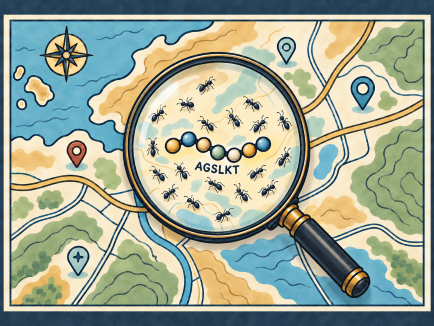

In [96]:
peptide

'IKALIRKWILRPIKRLKDKFWK'

In [120]:
NUMBER_OF_TRAJECTORIES = 1000
epsilon = 0.1
epsilon_squared = epsilon**2
time_horizon = 1.0
steps = int(time_horizon / epsilon_squared)
dim = 64

normal_updates = torch.randn(NUMBER_OF_TRAJECTORIES, steps, dim)
unit_updates = normal_updates / torch.linalg.norm(normal_updates, dim=2).unsqueeze(2)
scaled_updates = unit_updates * epsilon * torch.sqrt(torch.tensor(dim))
trajectories = torch.cumsum(scaled_updates, dim=1)

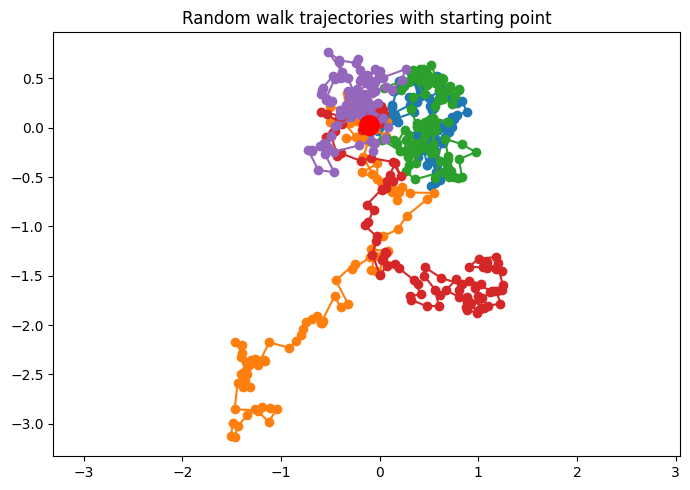

In [117]:
# @title Random walks { display-mode: "form" }

fig, ax = plt.subplots(figsize=(7, 5))

dims = (0, 1)
for i in range(NUMBER_OF_TRAJECTORIES):
    trajectory = trajectories[i, :, :]
    (line,) = ax.plot(
        trajectory[:, dims[0]].detach().cpu().numpy(),
        trajectory[:, dims[1]].detach().cpu().numpy(),
        marker="o",
        label=f"Trajectory {i + 1}",
    )

ax.scatter(trajectories[0, 0, dims[0]], trajectories[0, 0, dims[1]], color="red", s=200, zorder=5, label="Start (Origin)")

ax.set_title("Random walk trajectories with starting point")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

In [121]:
# @title Random walks animated { display-mode: "form" }


fig, ax = plt.subplots()

scatter = ax.scatter([], [], alpha=0.5)
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_xlabel("Dimension 0")
ax.set_ylabel("Dimension 1")


def update(frame):
    scatter.set_offsets(trajectories[:, 2 * frame, :2].detach().cpu().numpy())
    ax.set_title(f"Step {2 * frame + 1}/{trajectories.shape[1]}")
    return (scatter,)


animation = FuncAnimation(
    fig,
    update,
    frames=trajectories.shape[1] // 2,
    interval=50,
    blit=True,
)

plt.close(fig)
HTML(animation.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.

Question: what is this distribution?

In short: We adapted a random walk in the latent space so that it follows the geometry of the manifold. Again we used Jacobian of the decoder.

![Brownian Motion on a sphere](https://upload.wikimedia.org/wikipedia/commons/4/4e/BMonSphere.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled)



## 🐜 Random Walks + 🐎 MUTANG

Let's combine **Random walks** and **MUTANG**. In each step of a random walk we call **MUTANG** to get mutants.





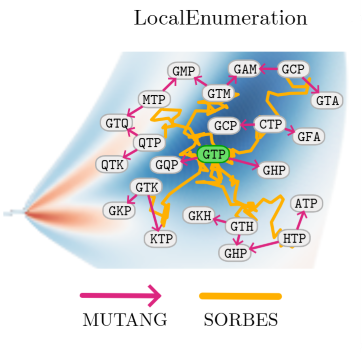

In [131]:
sampling_walker = SecondOrderRiemannianBrownianEfficientSampling(
    encoder_decoder=autoencoder,
)

local_enumerator = SamplingMutationLocalEnumerator(
    encoder_decoder=autoencoder,
    sampling_walker=sampling_walker,
    mutation_enumerator=mutang,
    device=DEVICE,
)

In [133]:
neighborhood = local_enumerator.local_enumeration(peptide)
len(neighborhood)

4926

In [135]:
# @title Neighbours in latent space { display-mode: "form" }


PCA_COMPONENTS = (0, 1)

latent_neighborhood = autoencoder.encode_peptides(neighborhood)

latent_neighborhood_projected = pca.transform(
    latent_neighborhood.detach().cpu().numpy()
)
peptide_latent_projected = pca.transform(peptide_latent.detach().cpu().numpy())

fig = go.Figure()

fig.add_trace(
    go.Scattergl(
        x=latent_background_projected[:, PCA_COMPONENTS[0]],
        y=latent_background_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Background peptides",
        marker={
            "size": 6,
            "opacity": 0.2,
            "color": "gray",
        },
        customdata=[
            (sequence,)
            for sequence in zip(
                background_peptides,
            )
        ],
        hovertemplate=("Sequence: %{customdata[0]}<br>"),
    )
)

fig.add_trace(
    go.Scattergl(
        x=latent_neighborhood_projected[:, PCA_COMPONENTS[0]],
        y=latent_neighborhood_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Neighborhood peptides",
        marker={
            "size": 12,
            "color": "blue",
            "opacity": 0.8,
        },
        customdata=np.column_stack((list(neighborhood),)),
        hovertemplate=("Sequence: %{customdata[0]}"),
    )
)

fig.add_trace(
    go.Scattergl(
        x=peptide_latent_projected[:, PCA_COMPONENTS[0]],
        y=peptide_latent_projected[:, PCA_COMPONENTS[1]],
        mode="markers",
        name="Original peptide",
        marker={"size": 14, "color": "red"},
        customdata=np.column_stack(([peptide],)),
        hovertemplate=("Sequence: %{customdata[0]}<br>"),
    )
)

fig.update_layout(
    title="PCA projection of latent positions",
    xaxis_title=f"PC{PCA_COMPONENTS[0]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[0]]:.1%} variance)",
    yaxis_title=f"PC{PCA_COMPONENTS[1]} ({pca.explained_variance_ratio_[PCA_COMPONENTS[1]]:.1%} variance)",
    template="plotly_white",
    width=900,
    height=650,
)

fig.show()

##  📉 Optimization


So far, we have only explored. We haven't yet used our Compass to **guide us toward peptides with high antimicrobial activity**. Now it's time to do so!

We assume that we have **limited number of the Oracle evaluations**.

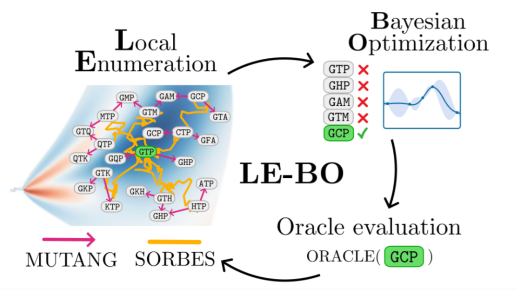

In [137]:
optimizer = LocalEnumerationBayesianOptimizer(
    black_box=apex_predictor,
    device=DEVICE,
    local_enumerator=local_enumerator,
)

observer = ListObserver(maximize=False)
apex_predictor.set_observer(observer)
observer.initialize_observer(
    apex_predictor.get_black_box_info(),
    {},
    42,
    encoder_decoder=autoencoder,
)

In [ ]:
optimizer.optimize(evaluation_budget=100, starting_point=peptide, rng_seed=42)

Observer: Best score so far: 3.4963815212249756 for sequence IKALIRKWILRPIKRLKDKFWK
Observer: Best score so far: 3.4963815212249756 for sequence IKALIRKWILRPIKRLKDKFWK
Observer: Best score so far: 3.4963815212249756 for sequence IKALIRKWILRPIKRLKDKFWK
Observer: Best score so far: 3.4963815212249756 for sequence IKALIRKWILRPIKRLKDKFWK
Observer: Best score so far: 3.1834189891815186 for sequence IKALIRKWITRPIKRLKAKLFYWK
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFIKRFKDKFWW
Observer: Best score so far: 2.8246936798095703 for sequence IKALIRKWILRFI

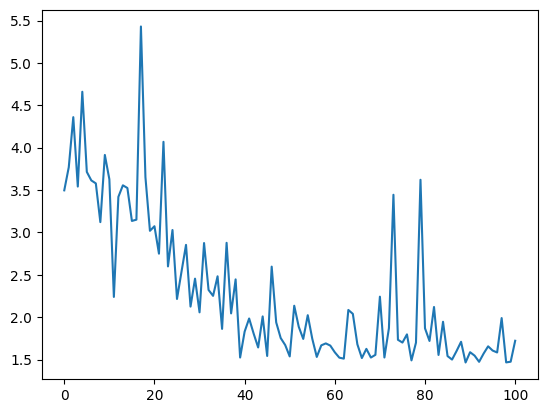

In [ ]:
plt.plot(observer.scores)
plt.xlabel("Iteration (Oracle Evaluation)")
plt.ylabel("Best Predicted log2 MIC Score")
plt.title("Optimization Progress: Local Enumeration Bayesian Optimizer")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()